In [553]:
import random

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [554]:
# read in all the words
words = open("../data/names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [555]:
len(words)

32033

In [556]:
# build the characters vocabulary and mappings to/from integers
chars = sorted(list(set("".join(words))))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}
stoi["."] = 0
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(itos)
vocab_size

27

In [557]:
# build the dataset
block_size = 3  # context length: how many characters do we take to predict the next one


def build_dataset(words):
    X, Y = [], []

    for w in words:
        context = [0] * block_size  # context, starting with 3 start characters '...'
        for ch in w + ".":  # ending each word with end character '.'
            ix = stoi[ch]
            X.append(context)
            Y.append(stoi[ch])
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(f"X.shape: {X.shape}; Y.shape: {Y.shape}")
    return X, Y


random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))  # 80% mark
n2 = int(0.9 * len(words))  # 90% mark

# split dataset: 80% train, 10% dev, 10% test
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

X.shape: torch.Size([182625, 3]); Y.shape: torch.Size([182625])
X.shape: torch.Size([22655, 3]); Y.shape: torch.Size([22655])
X.shape: torch.Size([22866, 3]); Y.shape: torch.Size([22866])


In [558]:
# MLP
n_emb = 10  # the dimensionality of the character embedding vectors
n_hidden = 200  # the number of neurons in the hidden layer of the MLP
n_input = block_size * n_emb  # number of inputs

seed = 2147483647
g = torch.Generator().manual_seed(seed)  # for reproducibility
C = torch.randn((vocab_size, n_emb), generator=g)  # embeddings lookup
W1 = (
    torch.randn((n_input, n_hidden), generator=g) * (5 / 3) / (n_input**0.5)
)  # tahn rectification
b1 = torch.randn(n_hidden, generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.rand(vocab_size, generator=g) * 0

# batch normalization
bngain = torch.ones((1, n_hidden))  # batch normalization gain
bnbias = torch.zeros((1, n_hidden))  # batch normalization bias
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
n_params = sum(p.nelement() for p in parameters)  # number of parameters in MLP

# allow gradients for backward pass
for p in parameters:
    p.requires_grad = True

n_params

12297

tensor(0.0186) tensor(0.9998)
tensor(-0.0006) tensor(0.9983)


(array([8.07254432e-06, 4.03627216e-06, 1.61450886e-05, 3.83445855e-05,
        4.64171298e-05, 1.00906804e-04, 1.75577839e-04, 2.88593459e-04,
        5.97368280e-04, 9.64669046e-04, 1.79614111e-03, 3.21287264e-03,
        5.79406868e-03, 9.38836904e-03, 1.59089667e-02, 2.62539323e-02,
        4.16805645e-02, 6.51111243e-02, 9.91631344e-02, 1.45172601e-01,
        2.01430162e-01, 2.69445384e-01, 3.36483829e-01, 3.92696991e-01,
        4.24208168e-01, 4.23838849e-01, 3.88703100e-01, 3.30512164e-01,
        2.61241661e-01, 1.95474643e-01, 1.38133342e-01, 9.43317166e-02,
        6.24633298e-02, 3.99712032e-02, 2.50612138e-02, 1.52571088e-02,
        8.87979875e-03, 5.27540771e-03, 3.25727163e-03, 1.76788721e-03,
        9.48523957e-04, 5.02515884e-04, 3.16847364e-04, 1.79614111e-04,
        7.66891710e-05, 4.23808577e-05, 3.02720412e-05, 1.41269526e-05,
        4.03627216e-06, 2.01813608e-06]),
 array([-6.18130827, -5.93355491, -5.68580154, -5.43804818, -5.19029482,
        -4.94254146, 

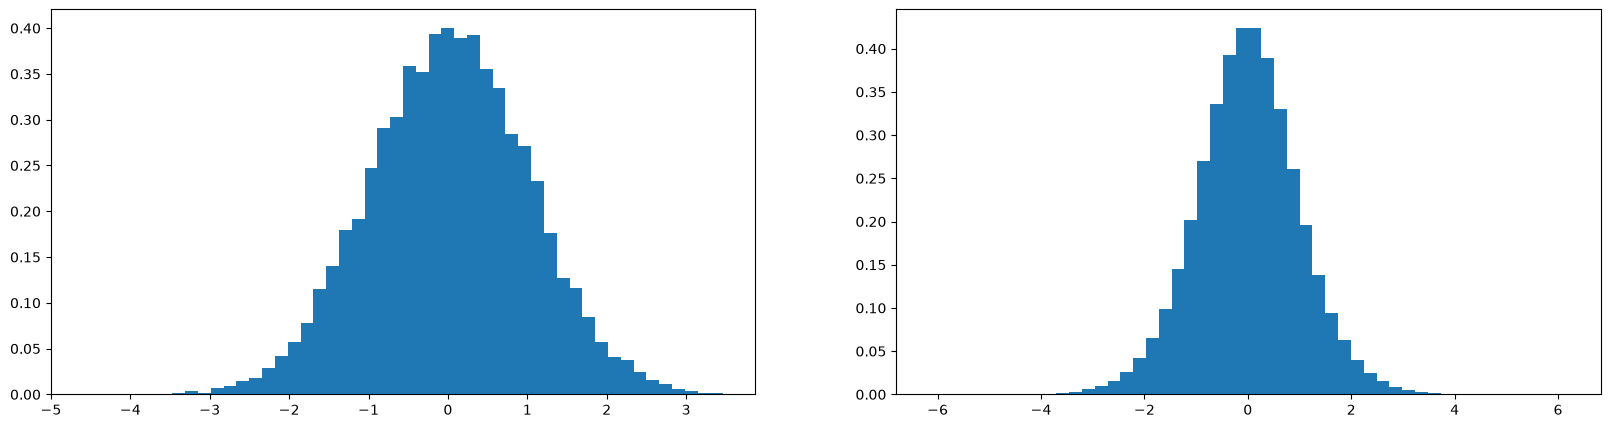

In [559]:
# theory on how to calculate the numbers with which we normalize the distributions
# example: we multiply W1 with 0.2 (magic number)
# there is a way to calculate these numbers using the Kaiming He et al. research paper:
# Delving Deep into Rectifiers: ....

# Goal we want y std deviation to be roughly the same as x std deviation
# For this we'll rectify the w layer (see the division part)
# In torch there is an implementation for this in torch.nn.init.kaiming_normal

# Below a simple toy sample for better understanding
x = torch.randn(1000, 10)
# note : applying rectification to w, we expect the same std deviation for y as for x
w = torch.randn(10, 2000) / (10**0.5)  # this is how square root of N is done sqrt(10)
y = x @ w  # this mimics our activation layer
print(x.mean(), x.std())
print(y.mean(), y.std())  # we want y std deviation be roughly the same as for x

plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True)

In [560]:
# training

max_steps = 200_000  # prod mode

batch_size = 32
lossi = []

for i in range(max_steps):

    # mini batch
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X, Y

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    embcat = emb.view(emb.shape[0], -1)  # concatenate the vectors
    hpreact = embcat @ W1 + b1  # hidden layer pre-activation

    # batch normalization: Batch normalization paper
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    h = torch.tanh(hpreact)  # hidden layer
    logits = h @ W2 + b2  # output layer
    loss = F.cross_entropy(logits, Yb)  # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100_000 else 0.01  # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10_000 == 0:  # print every 10_000th iteration
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())

    if i > 1000:
        break  # dev mode. uncomment when do real training

      0/ 200000: 3.2977


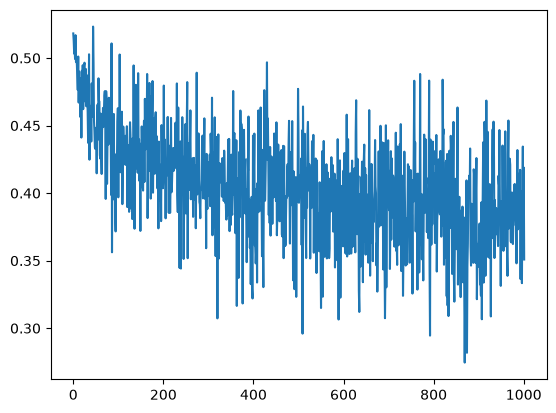

In [561]:
plt.plot(lossi)

In [562]:
# loss analysis (validation, test)


@torch.no_grad()  # disable gradient tracking (no need after the training)
def split_loss(split):
    x, y = {"train": (Xtr, Ytr), "val": (Xdev, Ydev), "test": (Xte, Yte)}[split]

    emb = C[x]  # (N, block_size, n_emb)
    embcat = emb.view(emb.shape[0], -1)  # concat to (N, block_size * n_emb)
    hpreact = embcat @ W1 + b1

    hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias

    h = torch.tanh(hpreact)  # (N, n_hidden)
    logits = h @ W2 + b2  # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())


split_loss("train")
split_loss("val")

train 2.453599452972412
val 2.451699733734131


In [563]:
# sample the model

g = torch.Generator().manual_seed(seed + 10)

for _ in range(20):

    out = []
    context = [0] * block_size  # initialize with all ...

    while True:  # forward pass the neural net
        emb = C[torch.tensor([context])]  # (1, block_size, n_emb)
        hpreact = emb.view(1, -1) @ W1 + b1
        hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
        h = torch.tanh(hpreact)
        logits = h @ W2 + b2
        probs = F.softmax(logits, dim=1)

        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()

        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:  # special token '.', break
            break

    # decode and print the generated word
    gen_word = "".join([itos[i] for i in out])
    print(gen_word)

carpahxqtelllelikimrixhlaty.
halans.
errahnen.
del.
rrc.
laqhiu.
ramari.
chaiiv.
kaleig.
dhli.
join.
qhinn.
shlin.
alianbi.
wazelondiarixi.
jameelinsab.
edde.
lia.
gtleley.
rey.


## Torch-ify

In [564]:
# Layers


class Linear:

    def __init__(self, fan_in, fan_out, bias=None):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:

    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters (trained with backpropagation)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # buffers (trained with a running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            xmean = x.mean(0, keepdim=True)  # batch mean
            xvar = x.var(0, keepdim=True)  # batch variance
        else:
            xmean = self.running_mean
            xvar = self.running_var

        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)  # normalize to unit variance
        self.out = self.gamma * xhat + self.beta

        # update the buffers
        if self.training:
            with torch.no_grad():
                self.running_mean = (
                    1 - self.momentum
                ) * self.running_mean + self.momentum * xmean
                self.running_var = (
                    1 - self.momentum
                ) * self.running_var + self.momentum * xvar

        return self.out

    def parameters(self):
        return [self.gamma, self.beta]


class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []


# Neural Network initialization

n_emb = 10  # the dimensionality of the character embedding vectors
n_hidden = 100  # the number or neurons in the hidden layer of the MLP
n_input = n_emb * block_size  # the number of input neurons
g = torch.Generator().manual_seed(seed)  # for reproducibility

C = torch.randn((vocab_size, n_emb), generator=g)
layers = [
    # 1st layer (input layer)
    Linear(n_input, n_hidden),
    BatchNorm1d(n_hidden),
    Tanh(),
    # 2nd layer
    Linear(n_hidden, n_hidden),
    BatchNorm1d(n_hidden),
    Tanh(),
    # 3d layer
    Linear(n_hidden, n_hidden),
    BatchNorm1d(n_hidden),
    Tanh(),
    # 4th layer
    Linear(n_hidden, n_hidden),
    BatchNorm1d(n_hidden),
    Tanh(),
    # 5th layer
    Linear(n_hidden, n_hidden),
    BatchNorm1d(n_hidden),
    Tanh(),
    # 6th layer (output layer)
    Linear(n_hidden, vocab_size),
    BatchNorm1d(vocab_size),
]

with torch.no_grad():
    # last layer, make less confident
    # layers[-1].weight *= 0.1  # this change done when last layer is Tanh()
    layers[-1].gamma *= 0.1  # this change is made if BatchNorm1d() layer is last
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5 / 3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))  # number of parameters in total
for p in parameters:
    p.requires_grad = True

47024


In [574]:
# Problem my code

# same optimization as last time
max_steps = 200_000  # prod mode
batch_size = 32
lossi = []
ud = []  # update to data ratio

# put layers into training mode (eval mode may be left on by the loss analysis cell)
for layer in layers:
    layer.training = True

for i in range(max_steps):

    # mini-batch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]  # batch X, Y

    # forward pass
    emb = C[Xb]  # embed the characters into vectors
    x = emb.view(emb.shape[0], -1)  # concatenate the vectors

    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)  # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad()  # AFTER_DEBUG: would take out retain_grad
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150_000 else 0.01  # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10_000 == 0:  # print stats every once in a while
        print(f"{i:7d}/{max_steps:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append(
            [(lr * p.grad.std() / p.data.std()).log10().item() for p in parameters]
        )

    if i > 1000:
        break  # AFTER_DEBUG: would take out to run full optimization

      0/ 200000: 2.4292


layer 2, (      Tanh): mean -0.00, std 0.63, saturated: 2.97%
layer 5, (      Tanh): mean +0.01, std 0.64, saturated: 2.41%
layer 8, (      Tanh): mean -0.00, std 0.64, saturated: 2.44%
layer 11, (      Tanh): mean +0.00, std 0.64, saturated: 2.22%
layer 14, (      Tanh): mean -0.00, std 0.64, saturated: 2.25%


Text(0.5, 1.0, 'activation distribution')

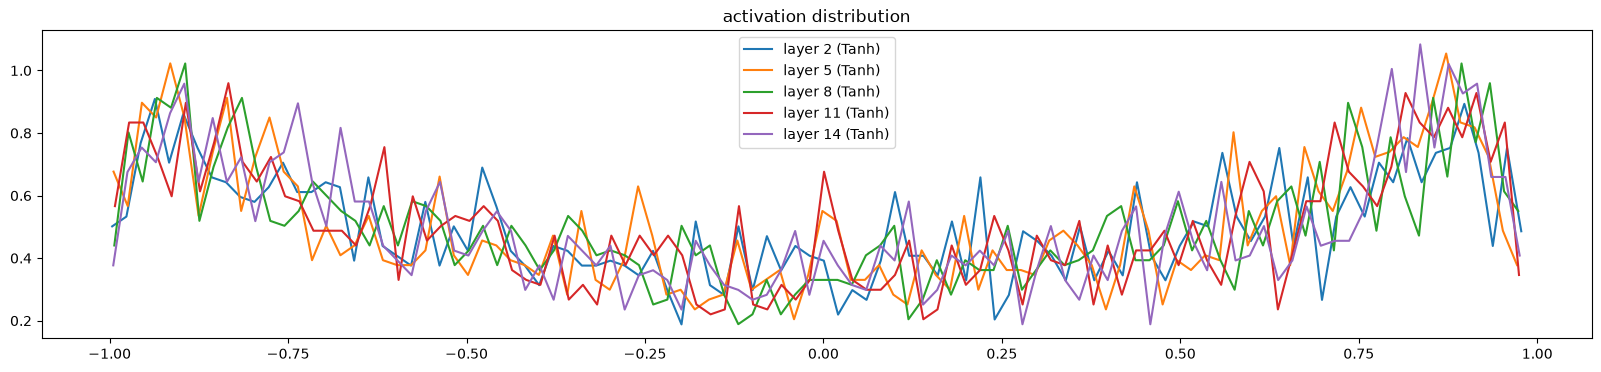

In [566]:
# visualize histograms - activation distribution
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]):  # exclude the output layer
    if isinstance(layer, Tanh):
        t = layer.out
        print(
            "layer %d, (%10s): mean %+.2f, std %.2f, saturated: %.2f%%"
            % (
                i,
                layer.__class__.__name__,
                t.mean(),
                t.std(),
                (t.abs() > 0.97).float().mean() * 100,
            )
        )
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title("activation distribution")

layer 2, (      Tanh): mean +0.000000, std 3.498291e-03
layer 5, (      Tanh): mean +0.000000, std 2.927728e-03
layer 8, (      Tanh): mean -0.000000, std 2.743274e-03
layer 11, (      Tanh): mean +0.000000, std 2.562695e-03
layer 14, (      Tanh): mean +0.000000, std 2.575432e-03


Text(0.5, 1.0, 'gradient distribution')

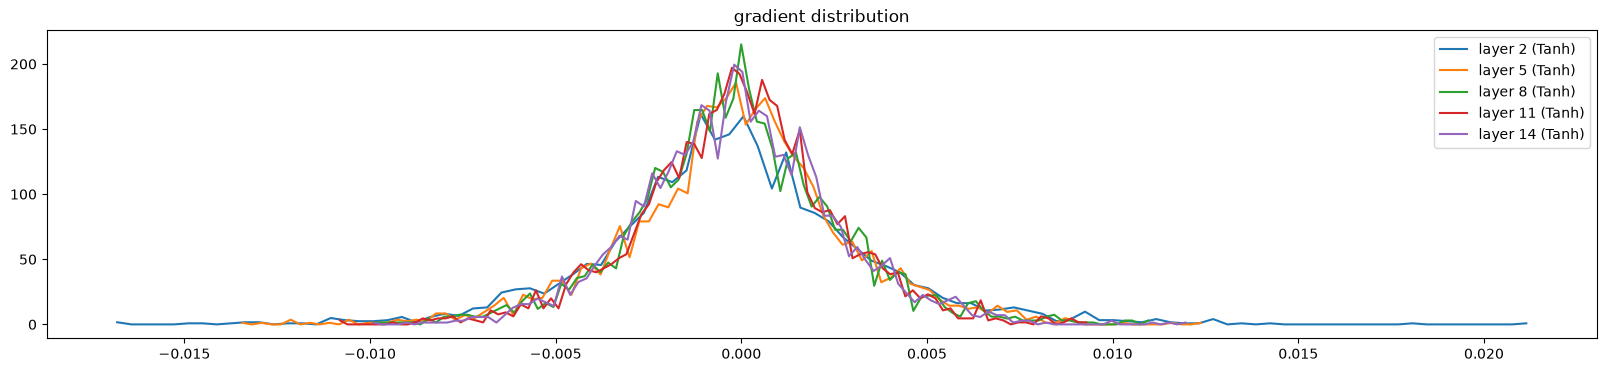

In [575]:
# visualize histograms - gradient distribution
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(layers[:-1]):  # exclude the output layer
    if isinstance(layer, Tanh):
        t = layer.out.grad
        print(
            "layer %d, (%10s): mean %+f, std %e"
            % (i, layer.__class__.__name__, t.mean(), t.std())
        )
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"layer {i} ({layer.__class__.__name__})")
plt.legend(legends)
plt.title("gradient distribution")

weight   (27, 10) | mean -0.000000 | std 8.198651e-03 | grad:data ratio 8.190292e-03
weight  (30, 100) | mean -0.000195 | std 7.650394e-03 | grad:data ratio 2.447697e-02
weight (100, 100) | mean -0.000097 | std 6.207570e-03 | grad:data ratio 3.712875e-02
weight (100, 100) | mean +0.000015 | std 5.561918e-03 | grad:data ratio 3.297628e-02
weight (100, 100) | mean +0.000008 | std 5.220601e-03 | grad:data ratio 3.110151e-02
weight (100, 100) | mean +0.000029 | std 4.829161e-03 | grad:data ratio 2.876369e-02
weight  (100, 27) | mean -0.000014 | std 9.281212e-03 | grad:data ratio 5.568815e-02


Text(0.5, 1.0, 'weights gradient distribution')

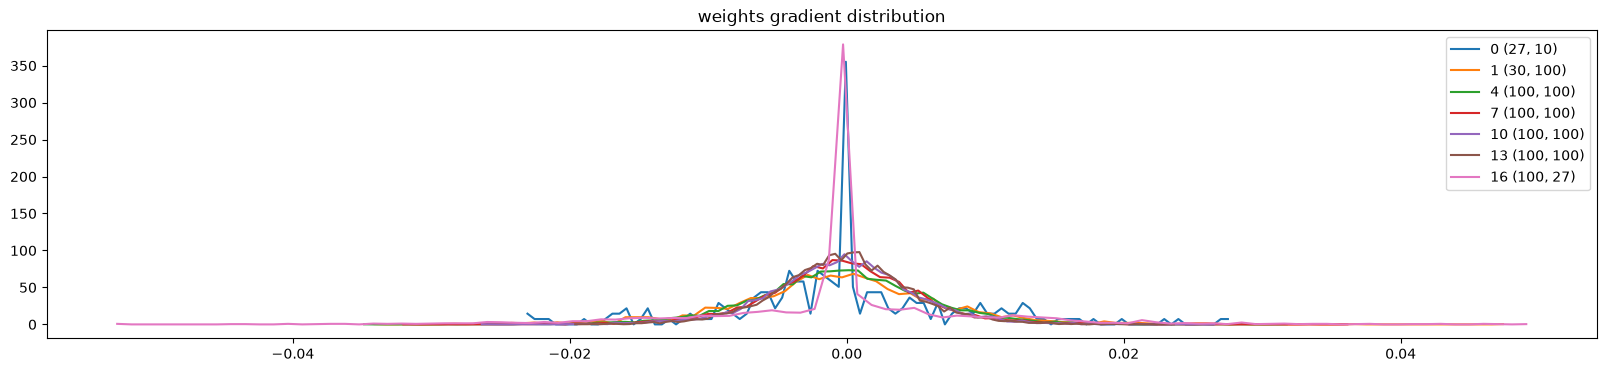

In [568]:
# visualize histograms
plt.figure(figsize=(20, 4))  # width and height of the plot
legends = []
for i, p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2:
        print(
            "weight %10s | mean %+f | std %e | grad:data ratio %e"
            % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std())
        )
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f"{i} {tuple(p.shape)}")
plt.legend(legends)
plt.title("weights gradient distribution")

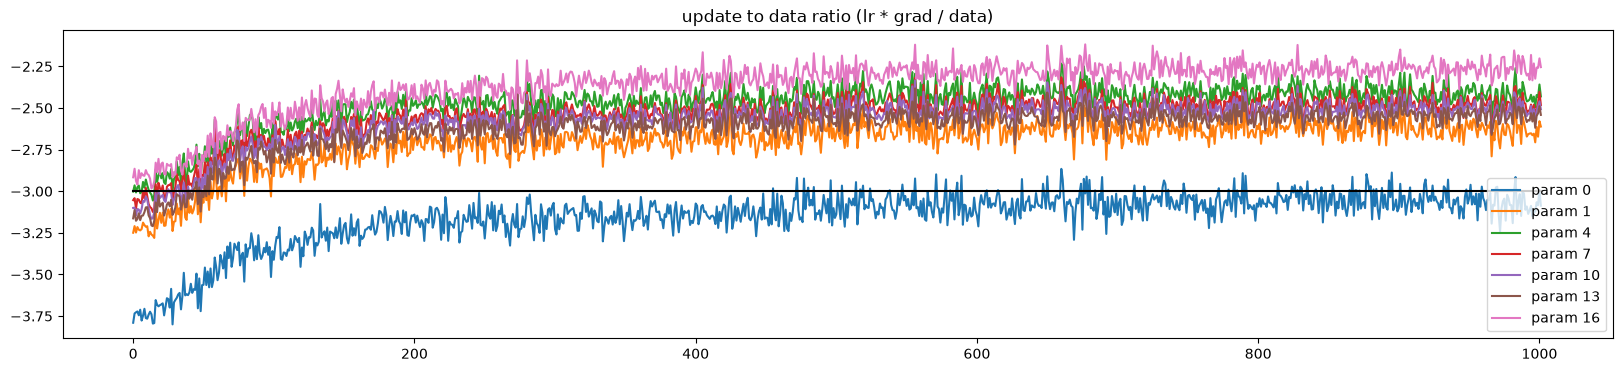

In [569]:
# visualize histograms - learning rate
plt.figure(figsize=(20, 4))
legends = []
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append("param %d" % i)

plt.plot([0, len(ud)], [-3, -3], "k")  # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);
plt.title("update to data ratio (lr * grad / data)");

In [570]:
# loss analysis (validation, test)


@torch.no_grad()  # disable gradient tracking (no need after the training)
def split_loss(split):
    x, y = {"train": (Xtr, Ytr), "val": (Xdev, Ydev), "test": (Xte, Yte)}[split]

    emb = C[x]  # (N, block_size, n_emb)
    x = emb.view(emb.shape[0], -1)  # concat to (N, block_size * n_emb)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, y)
    print(split, loss.item())


# put layers into eval mode
for layer in layers:
    layer.training = False

split_loss("train")
split_loss("val")

train 2.431868553161621
val 2.4297308921813965


In [571]:
# sample the model

g = torch.Generator().manual_seed(seed + 10)

for _ in range(20):

    out = []
    context = [0] * block_size  # initialize with all ...

    while True:  # forward pass the neural net
        emb = C[torch.tensor([context])]  # (1, block_size, n_emb)
        x = emb.view(emb.shape[0], -1)  # concatenate vectors
        for layer in layers:
            x = layer(x)
        logits = x
        probs = F.softmax(logits, dim=1)

        # sample from the distribution
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()

        # shift the context window and track the samples
        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:  # special token '.', break
            break

    # decode and print the generated word
    gen_word = "".join([itos[i] for i in out])
    print(gen_word)

carpah.
qarlilvif.
jmrri.
thty.
sacansa.
jazhntefapliah.
jagqeiu.
ramara.
chriiv.
kalein.
dhlm.
join.
qhijthn.
lilea.
jadbq.
wazerogdearyxi.
jaheininsan.
ed.
ecoia.
gtleley.
